# Занятие 6. Токенный бюджет, мониторинг и ограничение потребления

# Введение

Ассистент уже умеет находить фрагменты корпоративных документов, формировать структурированный ответ и сохранять фактическое потребление API. Но отдельные измерения ещё не образуют эксплуатационный контур. До вызова приложение должно оценить будущий расход, решить, разрешён ли запрос, после вызова – записать фактические токены и обновить квоту, а затем проверить пороги оповещений и эффективность затрат.

На этом занятии мы соберём такой контур вокруг GigaChat. Основной исполняемый путь использует `GigaChat-2`, а векторизация вопроса выполняется через `EmbeddingsGigaR`. Один настоящий запрос покажет, как учитывать расход токенов при работе с GigaChat. Учебные данные помогут построить графики потребления, проверить ограничения и увидеть, как система сообщает о достижении заданного уровня квоты, не выполняя десятки платных запросов.

# Подготовка окружения

Версии соответствуют предыдущим занятиям. Установка закомментирована, чтобы повторный запуск уже настроенного ноутбука не менял окружение.

В установочной ячейке фиксируем версию официального SDK `gigachat`, чтобы примеры не менялись вместе с несовместимым обновлением библиотеки. `pydantic` нужен для контрактов структурированных данных в проекте, а `pandas` и `matplotlib` – для табличного анализа и визуализации результатов. В Colab эту ячейку выполняют один раз в начале сессии; после изменения пакетов среда может попросить перезапустить ядро.


In [ ]:
%%capture
%pip -q install \
    "openai==3.40.0" \
    "pydantic>=2.7,<3" \
    "pandas>=2.2,<3" \
    "matplotlib>=3.8,<4" \
    "transformers==5.16.1" \
    "langgraph>=1.0,<2"

In [ ]:
import json
import os
import re
import uuid
import html
import asyncio
from contextvars import ContextVar

from collections import Counter
from dataclasses import asdict, dataclass, replace
from decimal import Decimal
from getpass import getpass
from math import ceil
from time import perf_counter
from typing import Any, Iterable, Literal, Mapping, TypedDict

import matplotlib.pyplot as plt
import pandas as pd

from openai import OpenAI
from langgraph.graph import StateGraph, START, END

from transformers import AutoTokenizer
from IPython.display import display, HTML

In [ ]:
import getpass




Вставьте ваш ключ авторизации `gigachat`:

In [ ]:
GIGACHAT_KEY = getpass.getpass()

Подключите модель и проверьте работоспособность

In [ ]:
client = OpenAI(
    api_key=GIGACHAT_KEY,
    base_url="https://foundation-models.api.cloud.ru/v1",
    timeout=120,
)
llm_model = "GigaChat/GigaChat-3-Pro"

session_id_cvar = ContextVar("cloudru_session_id", default=None)

In [ ]:
print(client.chat.completions.create(
    model=llm_model,
    messages=[{"role": "user", "content": "Кто ты?"}],
).choices[0].message.content)

In [ ]:
def print_table(rows: list[dict[str, Any]], columns: list[str] | None = None) -> None:
    'Печатает компактную таблицу без обязательной зависимости от pandas.'
    if not rows:
        print("Нет данных")
        return
    columns = columns or list(rows[0])
    values = [[str(row.get(column, "")) for column in columns] for row in rows]
    widths = [
        max(len(str(column)), *(len(row[index]) for row in values))
        for index, column in enumerate(columns)
    ]
    print(" | ".join(str(column).ljust(widths[index]) for index, column in enumerate(columns)))
    print("-+-".join("-" * width for width in widths))
    for row in values:
        print(" | ".join(value.ljust(widths[index]) for index, value in enumerate(row)))


def model_to_dict(value: Any) -> dict[str, Any]:
    """Преобразует объект SDK или словарь к обычному dict."""
    if value is None:
        return {}
    if isinstance(value, dict):
        return value
    if hasattr(value, "model_dump"):
        return value.model_dump()
    if hasattr(value, "dict"):
        return value.dict()
    return {"value": value}

# Подсчет токенов

В этом разделе поговорим, как можно подсчитать и оценить кол-во токенов в тексте.

In [ ]:
text1 = """
Количество токенов можно определить непосредственно с помощью **токенизатора модели**, если он доступен пользователю.
Такой способ позволяет заранее узнать, на какое количество токенов будет разбит конкретный текст, ещё до отправки запроса к модели.
Для закрытых моделей токенизатор доступен не всегда, однако для всех открытых моделей токенизаторы, публикуются вместе с моделью.
Иногда токенизатор выкладывается в открытый доступ даже для проприетарных моделей, поскольку сам по себе он не содержит основную
часть знаний и вычислительных возможностей LLM.
"""

text2 = """
В примере ниже мы вернемся к токенизатору **GigaChat 3.5**. Хотя сама модель является проприетарной и используется преимущественно через API,
её токенизатор доступен отдельно. Это позволяет локально воспроизвести разбиение текста на токены и оценить размер запроса без непосредственного
обращения к модели. Если несколько моделей одной линейки используют один и тот же токенизатор, такой подход можно применять и для оценки запросов
к другим моделям этой линейки. Однако это предположение необходимо предварительно проверять: разные версии моделей могут использовать различные
словари или настройки токенизации.
"""

text3 = """
Как видно из примера, разные токенизаторы по-разному представляют тексты на разных языках. Токенизатор GigaChat, ориентированный в том числе
на русский язык, чаще встречал русскоязычные последовательности при обучении и поэтому способен представлять многие русские слова и их части более
крупными токенами. Токенизатор Qwen, напротив, лучше адаптирован к китайскому тексту и чаще объединяет характерные для китайского языка последовательности
в крупные токены. При этом английский текст оба токенизатора обрабатывают достаточно эффективно, поэтому различия в количестве токенов для него обычно
оказываются менее выраженными. Из этого следует важный практический вывод: **характеристики токенизатора непосредственно влияют на стоимость обработки
текста моделью**. Чем меньше токенов требуется для представления одного и того же текста, тем меньше вычислений необходимо как при обработке входного
контекста, так и при последующей генерации.
"""

text4 = """
As the example illustrates, different tokenizers represent text in different languages in different ways. The GigaChat tokenizer, which is
designed with Russian among its target languages, encountered Russian-language sequences more frequently during training and can therefore
represent many Russian words and word fragments using larger tokens. The Qwen tokenizer, by contrast, is better adapted to Chinese text
and more frequently combines sequences characteristic of the Chinese language into larger tokens. At the same time, both tokenizers process
English text relatively efficiently, so differences in token counts for English are generally less pronounced. This leads to an important practical
conclusion: the characteristics of a tokenizer directly affect the computational cost of processing text with a language model. The fewer tokens
required to represent the same text, the less computation is needed both to process the input context and to generate the subsequent output.
"""

text5 = """
从上述示例可以看出，不同的分词器（Tokenizer）在处理不同语言的文本时，会采用不同的表示方式。GigaChat 的分词器在设计时考虑了俄语等目标语言，
因此在训练过程中接触到了更多的俄语文本序列，能够将许多俄语单词及其组成部分表示为更大的词元（Token）。相比之下，Qwen 的分词器对中文文本的适应性更强，
更倾向于将中文中常见的字符序列合并为较大的词元。与此同时，两种分词器都能够较为高效地处理英语文本，因此在处理英语时，它们生成的词元数量通常不会存在特别显著的差异。
由此可以得出一个重要的实践结论：分词器的特性会直接影响语言模型处理文本的计算成本。对于同一段文本，所需的词元数量越少，模型在处理输入上下文以及随后生成输出时所需的计算量就越少。
"""


In [ ]:
TOKENIZATION_SAMPLES = {
    "Обычный текст 1 (ru)": text1,
    "Обычный текст 2 (ru)": text2,
    "Обычный текст 3 (ru)": text3,
    "Обычный текст 4 (en)": text4,
    "Обычный текст 5 (ch)": text5,
    "Редкое слово": "электрофотополупроводниковый",
    "Структурированный ответ": '{"label":"conditional","source_ids":["trip_02","sick_01"]}',
    "Числа и время": "Лимит – 128 000 токенов; вылет в 05:30.",
    "Пустая строка": ""
}


def word_like_tokens(text: str) -> list[str]:
    """Делит строку на слова и отдельные знаки пунктуации."""
    return re.findall(r"\w+|[^\w\s]", text, flags=re.UNICODE)


rows = []
for label, text in TOKENIZATION_SAMPLES.items():
    rows.append({
        "Пример": label,
        "Символы": len(text),
        "UTF-8 байты": len(text.encode("utf-8")),
        "Слова и знаки": len(word_like_tokens(text)),
    })
print_table(rows)







## Подсчет через API

GigaChat предоставляет два источника данных.
- `POST /tokens/count` оценивает переданный текст до генерации.
- Объект `usage` после `POST /chat/completions` показывает фактические входные, выходные, кэшированные и оплачиваемые токены.

По документации `/tokens/count` не предсказывает ответ и не оценивает изображения или файлы. Поэтому предварительный счётчик используется для планирования, а `usage` – для окончательного учёта.

Подробности — в [документации по подсчёту токенов](https://developers.sber.ru/docs/ru/gigachat/guides/counting-tokens).



In [ ]:
def count_prompt_tokens_via_api(text: str) -> int:
    # В OpenAI-совместимом API здесь используем usage после минимальной генерации.
    # Это платный вызов; prompt_tokens включает обрамление сообщения (роль и т.п.).
    response = client.chat.completions.create(
        model=llm_model,
        messages=[{"role": "user", "content": text}],
        max_tokens=1,
    )
    return response.usage.prompt_tokens


reasoning_token_counts = [
    count_prompt_tokens_via_api(text)
    for text in ["Привет, как дела?", "Как дела, как дела"]
]
print(reasoning_token_counts)


In [ ]:
table = []

for rtype, text in TOKENIZATION_SAMPLES.items():
    table.append({
        "Тип текста": rtype,
        "Кол-во символов": len(text),
        "Кол-во токенов": count_prompt_tokens_via_api(text) - 1215,
    })
print_table(table)


## Подсчет через токенизатор

Количество токенов можно определить непосредственно с помощью **токенизатора модели**, если он доступен пользователю. Такой способ позволяет заранее узнать, на какое количество токенов будет разбит конкретный текст, ещё до отправки запроса к модели.

Для закрытых моделей токенизатор доступен не всегда, однако для всех открытых моделей токенизаторы, публикуются вместе с моделью. Иногда токенизатор выкладывается в открытый доступ даже для проприетарных моделей, поскольку сам по себе он не содержит основную часть знаний и вычислительных возможностей LLM.

В примере ниже мы вернемся к токенизатору **GigaChat 3.5**. Хотя сама модель является проприетарной и используется преимущественно через API, её токенизатор доступен отдельно. Это позволяет локально воспроизвести разбиение текста на токены и оценить размер запроса без непосредственного обращения к модели.

Если несколько моделей одной линейки используют один и тот же токенизатор, такой подход можно применять и для оценки запросов к другим моделям этой линейки. Однако это предположение необходимо предварительно проверять: разные версии моделей могут использовать различные словари или настройки токенизации.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    "ai-sage/GigaChat3.5-432B-A28B-Reasoning",
    use_fast=True,
)

In [ ]:
table = []
for rtype in TOKENIZATION_SAMPLES:
    ntokens = len(tokenizer.encode(TOKENIZATION_SAMPLES[rtype]))
    table.append({
        "Тип текста": rtype,
        "Кол-во символов": len(TOKENIZATION_SAMPLES[rtype]),
        "Кол-во токенов": ntokens,
        "Символов/токен": round(len(TOKENIZATION_SAMPLES[rtype]) / ntokens, 2)
    })
print_table(table)

## Подсчет через оценку


Три уровня, по убыванию точности:

1. **счётчик платформы** на адресе, где он работает — точное число;
2. **локальная оценка** по числу символов с коэффициентом, откалиброванным на нашем корпусе — приблизительно;
3. явная пометка, каким способом получено число, чтобы оценка не смешивалась с фактом.

Третий пункт важнее, чем кажется: смешав оценку с фактом в одной таблице, вы получите числа, которым нельзя верить, и не заметите этого.

In [ ]:
# Коэффициент локальной оценки: сколько символов приходится на токен.
# Значение подбирается на своём корпусе — как именно, покажем ниже.
CHARS_PER_TOKEN_ESTIMATE = 5.1

table = []
for rtype in TOKENIZATION_SAMPLES:
    ntokens_api = count_prompt_tokens_via_api(TOKENIZATION_SAMPLES[rtype]) - 1215
    ntokens_tok = len(tokenizer.encode(TOKENIZATION_SAMPLES[rtype]))
    ntokens_est = max(1, round(len(TOKENIZATION_SAMPLES[rtype]) / CHARS_PER_TOKEN_ESTIMATE))

    table.append({
        "Тип текста": rtype,
        "Кол-во символов": len(TOKENIZATION_SAMPLES[rtype]),
        "Кол-во токенов по API": ntokens_api,
        "Кол-во токенов по токенизатору": ntokens_tok,
        "Кол-во токенов по оценке": ntokens_est,
        "Разница в %": round((1 - ntokens_api/ntokens_est) * 100, 1)
    })
print_table(table)

# Расчёт стоимости обращения к LLM

На прошлом занятии мы научились оценивать количество токенов. Теперь эти измерения позволят рассчитать стоимость обращения к модели и выяснить, какие части запроса формируют основные расходы. В качестве примера будем использовать небольшого помощника, который отвечает на вопросы о клиентах по сведениям из условной CRM-системы.

- **Промпт** включает системную инструкцию и текущий вопрос пользователя,
- **история диалога** содержит предшествующие сообщения,
- **внешний контекст** представляет полученные из CRM сведения, а
- **генерация** является ответом модели.

Все три входных компонента передаются модели вместе с запросом, тогда как выходные токены появляются в процессе генерации.

## Тарифы и оплачиваемые токены

Во многих LLM API стоимость входных и выходных токенов различается. В общем случае стоимость одного обращения можно выразить следующей формулой.

$$C=\frac{T_{\mathrm{in}}P_{\mathrm{in}}+T_{\mathrm{out}}P_{\mathrm{out}}}{10^6}$$

Здесь $T_{\mathrm{in}}$ и $T_{\mathrm{out}}$ обозначают количество оплачиваемых входных и выходных токенов, а $P_{\mathrm{in}}$ и $P_{\mathrm{out}}$ задают тарифы за миллион токенов. Если провайдер поддерживает кэширование входного контекста, кэшированные токены необходимо учитывать отдельно.

В GigaChat для рассматриваемого синхронного тарифа **одна ставка применяется к суммарному количеству оплачиваемых токенов**. Поэтому далее стоимость рассчитывается по полю `usage.total_tokens`. Для демонстрации используется ставка pay-as-you-go, которая может отличаться от стоимости предоплаченного пакета или условий конкретного договора. Минимальный месячный платёж и другие договорные условия в учебных расчётах не учитываются. Тарифы доступны в [документации GigaChat](https://developers.sber.ru/docs/ru/gigachat/tariffs/legal-tariffs).

In [ ]:
# Учебные тарифы синхронных обращений в рублях за 1 млн токенов.
PRICES = {"GigaChat-2": 65, "GigaChat-2-Pro": 500, "GigaChat-3-Pro": 650}
MAIN_MODEL = llm_model
PRICES[MAIN_MODEL] = PRICES["GigaChat-3-Pro"]  # учебный тариф для расчётов, не цена Cloud.ru

SYSTEM_PROMPT = "Ты помощник менеджера по продажам. Используй данные CRM и отвечай кратко."
HISTORY = [
    {"role": "user", "content": "Сколько сделок у клиента Альфа?"},
    {"role": "assistant", "content": "У клиента Альфа две сделки."},
]
CRM_CONTEXT = "Клиент Альфа. Сделка А на 120000 рублей, сделка Б на 80000 рублей."
QUESTION = "Какова общая сумма двух сделок в рублях? Ответь только числом."

DEV_PROMPT_LENGTH = 1216

## Выполнение запроса и сбор статистики

Сначала создадим небольшую функцию для формирования сообщений. История диалога передаётся как отдельные сообщения, а сведения CRM включаются в последний запрос. Отдельной реализации поиска по документам здесь не требуется, поскольку в данном примере контекст уже известен.

Затем выполним обращение к GigaChat и сохраним фактические показатели `usage` вместе со временем выполнения. Дальше эта же функция будет использоваться во всех графах, поэтому формат метрик останется одинаковым.

In [ ]:
def make_messages(question, history=(), context="", instruction=SYSTEM_PROMPT):
    messages = [{"role": "system", "content": instruction}]
    for item in history:
        role = "user" if item["role"] == "user" else "assistant"
        messages.append({"role": role, "content": item["content"]})

    current = (f"Контекст CRM\n{context}\n\n" if context else "") + question
    messages.append({"role": "user", "content": current})
    return messages

In [ ]:
def call_llm(question, history=(), context="", model=MAIN_MODEL,
             instruction=SYSTEM_PROMPT, task="answer"):
    started = perf_counter()
    session_id = session_id_cvar.get()
    response = client.chat.completions.create(
        model=model,
        messages=make_messages(question, history, context, instruction),
        temperature=0.7,
        max_tokens=120,
        **({"extra_headers": {"X-Session-ID": session_id}} if session_id else {}),
    )
    usage = response.usage
    # Некоторые провайдеры возвращают GigaChat-совместимое поле, другие — поле OpenAI.
    legacy_cached = getattr(usage, "precached_prompt_tokens", None)
    details = getattr(usage, "prompt_tokens_details", None)
    cached_tokens = (
        legacy_cached if legacy_cached is not None
        else getattr(details, "cached_tokens", 0) or 0
    )
    gross_input_tokens = (
        usage.prompt_tokens + cached_tokens
        if legacy_cached is not None else usage.prompt_tokens
    )
    paid_tokens = usage.total_tokens - cached_tokens

    return {
        "answer": (response.choices[0].message.content or "").strip(),
        "model": model, "task": task, "status": "ok",
        "input_tokens": usage.prompt_tokens - DEV_PROMPT_LENGTH,
        "cached_tokens": cached_tokens,
        "gross_input_tokens": gross_input_tokens,
        "output_tokens": usage.completion_tokens,
        "paid_tokens": paid_tokens,
        "cost_rub": paid_tokens * PRICES[model] / 1_000_000,
        "latency_s": perf_counter() - started,
        "question": question, "history": list(history), "context": context,
        "instruction": instruction,
    }


In [ ]:
first_call = call_llm(QUESTION, HISTORY, CRM_CONTEXT)

print("Ответ модели:", first_call["answer"])
print("Входные оплачиваемые токены:", first_call["input_tokens"])
print("Кэшированные токены:", first_call["cached_tokens"])
print("Выходные токены:", first_call["output_tokens"])
print(f"Стоимость {first_call['cost_rub']:.5f} ₽")

## Распределение стоимости между компонентами

Сервис возвращает фактическое потребление для всего входного запроса, но не разделяет его на промпт, историю диалога и контекст CRM. Для такого разложения воспользуемся **локальной оценкой долей компонентов** с помощью уже знакомого токенизатора. Затем распределим фактические входные токены пропорционально полученным долям. При наличии кэша такое распределение стоимости также будет приближённым, поскольку отдельные попадания в кэш не привязаны к конкретному компоненту.

Таким образом, общее количество токенов и стоимость будут основаны на `usage`, а разбивка входа по компонентам останется аналитической оценкой. Именно это различие следует сохранять при построении любой системы мониторинга.

In [ ]:
local_tokenizer = tokenizer

In [ ]:
def breakdown(call):
    history_text = " ".join(message["content"] for message in call["history"])
    texts = {
        "Промпт": call["instruction"] + call["question"],
        "История": history_text,
        "Контекст CRM": call["context"],
    }
    weights = {name: len(local_tokenizer.encode(text, add_special_tokens=False))
               for name, text in texts.items()}
    weight_sum = sum(weights.values())
    gross_input = call["gross_input_tokens"]

    rows = [{
        "Компонент": name,
        "Токены": gross_input * weight / weight_sum,
        "Стоимость, ₽": call["input_tokens"] * weight / weight_sum
                        * PRICES[call["model"]] / 1_000_000,
    } for name, weight in weights.items()]
    rows.append({"Компонент": "Генерация", "Токены": call["output_tokens"],
                 "Стоимость, ₽": call["output_tokens"] * PRICES[call["model"]] / 1_000_000})
    return pd.DataFrame(rows)

In [ ]:
parts = breakdown(first_call)
display(parts.round(5))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, column, title in zip(
    axes, ["Токены", "Стоимость, ₽"],
    ["Количество токенов", "Оценка стоимости по компонентам"],
):
    ax.bar(parts["Компонент"], parts[column], color="#e1a886")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=20)
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

> **Вопрос**
>
> Почему история диалога и внешний контекст увеличивают стоимость генерации, даже если ответ модели остаётся коротким?
>
> - **А.** Они увеличивают количество входных токенов, учитываемых при тарификации.
> - **Б.** Они увеличивают цену каждого выходного токена независимо от тарифа.
> - **В.** Они увеличивают максимальный размер словаря токенизатора модели.
> - **Г.** Они увеличивают число ответов, генерируемых моделью за один вызов.

<details>
<summary>Ответ</summary>

**Правильный ответ А.**

**А.** История и внешний контекст входят в передаваемую последовательность и увеличивают число входных токенов.

**Б.** Цена выходного токена определяется тарифом и не меняется автоматически из-за наличия истории.

**В.** Размер словаря определяется моделью и не зависит от содержимого конкретного запроса.

**Г.** Один вызов по-прежнему формирует один ответ, если дополнительно не настроена множественная генерация.

</details>

# Стоимость различных стратегий работы с LLM

Одно обращение к модели является только частным случаем работы LLM-приложения. Для повышения устойчивости ответа можно запрашивать несколько независимых решений или организовывать поиск по альтернативным рассуждениям. Такие подходы изменяют количество обращений к модели и суммарную стоимость.

Сравним три небольших графа, используя **LangGraph**. Во всех примерах сохраним одну и ту же задачу, модель и тариф, чтобы различие было связано прежде всего со структурой выполнения.

## Базовый граф

Состояние графа будет содержать вопрос, историю диалога, контекст, ответы и записи о вызовах LLM. Каждая запись представляет один фактический вызов с уже рассчитанными токенами, стоимостью и задержкой.

Базовый граф выполняет одну генерацию и возвращает её результат.

In [ ]:
class AgentState(TypedDict, total=False):
    question: str
    history: list[dict]
    context: str
    answers: list[str]
    calls: list[dict]
    final_answer: str
    retry_mode: bool
    failure_case: str


def generate_answer(state: AgentState):
    if state.get("retry_mode", False):
        case = state.get("failure_case", "none") if not state["answers"] else "none"
        attempts = run_with_retries(state["question"], state["history"], state["context"], case)
    else:
        attempts = [call_llm(state["question"], state["history"], state["context"])]
    return {
        "answers": state["answers"] + [attempts[-1]["answer"]],
        "calls": state["calls"] + attempts,
    }


def vote(state: AgentState):
    variants = [re.search(r"-?\d+(?:[.,]\d+)?", answer)
                for answer in state["answers"]]
    answers = [match.group() if match else answer.strip() for match, answer
               in zip(variants, state["answers"])]
    return {"final_answer": Counter(answers).most_common(1)[0][0]}

In [ ]:
baseline_builder = StateGraph(AgentState)
baseline_builder.add_node("generate", generate_answer)
baseline_builder.add_node("finish", vote)
baseline_builder.add_edge(START, "generate")
baseline_builder.add_edge("generate", "finish")
baseline_builder.add_edge("finish", END)
baseline_graph = baseline_builder.compile()

In [ ]:
baseline_graph

In [ ]:
EXAMPLE = {
    "question": QUESTION,
    "history": HISTORY,
    "context": CRM_CONTEXT,
    "answers": [],
    "calls": [],
    "retry_mode": False
}

baseline_run = baseline_graph.invoke(EXAMPLE)
print("Ответ:", baseline_run["final_answer"])
print("Вызовов LLM:", len(baseline_run["calls"]))

## Self-consistency

Метод self-consistency получает несколько независимых ответов на один вопрос и выбирает наиболее частый результат. В нашем примере модель вызывается три раза, а голосование выполняется обычным кодом и не требует дополнительного обращения к LLM.

Будем повторно использовать уже созданный узел генерации. В граф добавится только условие, определяющее, достаточно ли ответов для голосования. Если все три ответа различаются, упрощённая реализация выбирает первый из них, тогда как в реальной системе потребуется отдельное правило разрешения ничьей.

In [ ]:
def next_step(state: AgentState):
    return "vote" if len(state["answers"]) >= 3 else "generate"

consistency_builder = StateGraph(AgentState)
consistency_builder.add_node("generate", generate_answer)
consistency_builder.add_node("vote", vote)
consistency_builder.add_edge(START, "generate")
consistency_builder.add_conditional_edges("generate", next_step, ["generate", "vote"])
consistency_builder.add_edge("vote", END)
consistency_graph = consistency_builder.compile()

In [ ]:
consistency_graph

In [ ]:
consistency_run = consistency_graph.invoke(EXAMPLE)
print("Варианты", consistency_run["answers"])
print("Результат голосования", consistency_run["final_answer"])

## Tree of Thoughts

Tree of Thoughts позволяет исследовать несколько направлений рассуждения и сравнивать полученные результаты. Для учебного примера ограничимся небольшим деревом с двумя ветвями. Сначала модель предлагает два подхода, затем формируются два независимых решения, после чего модель выбирает окончательный ответ.

В отличие от self-consistency здесь появились разные типы обращений к LLM. Каждый из них имеет собственный промпт и может потреблять различное количество токенов.

In [ ]:
class TreeState(TypedDict, total=False):
    question: str
    history: list[dict]
    context: str
    plan: str
    answer_a: str
    answer_b: str
    record_plan: dict
    record_a: dict
    record_b: dict
    calls: list[dict]
    final_answer: str


def plan_node(state: TreeState):
    prompt = f"Предложи два разных коротких способа решения задачи. {state['question']}"
    record = call_llm(prompt, state["history"], state["context"], task="plan")
    return {"plan": record["answer"], "record_plan": record}


def branch_node(state: TreeState, number: int):
    prompt = (f"Задача. {state['question']}\nПодходы. {state['plan']}\n"
              f"Реши задачу способом {number} и дай только числовой ответ.")
    record = call_llm(prompt, state["history"], state["context"], task=f"branch_{number}")
    suffix = "a" if number == 1 else "b"
    return {f"answer_{suffix}": record["answer"], f"record_{suffix}": record}


def select_node(state: TreeState):
    prompt = (f"Вопрос. {state['question']}\nПервое решение. {state['answer_a']}\n"
              f"Второе решение. {state['answer_b']}\nВыбери правильный числовой ответ.")
    record = call_llm(prompt, context=state["context"], task="select")
    calls = [state["record_plan"], state["record_a"], state["record_b"], record]
    return {"calls": calls, "final_answer": record["answer"]}

In [ ]:
tree_builder = StateGraph(TreeState)
tree_builder.add_node("plan", plan_node)
tree_builder.add_node("branch_a", lambda state: branch_node(state, 1))
tree_builder.add_node("branch_b", lambda state: branch_node(state, 2))
tree_builder.add_node("select", select_node)

tree_builder.add_edge(START, "plan")
tree_builder.add_edge("plan", "branch_a")
tree_builder.add_edge("plan", "branch_b")
tree_builder.add_edge(["branch_a", "branch_b"], "select")
tree_builder.add_edge("select", END)

tree_graph = tree_builder.compile()

In [ ]:
tree_graph

In [ ]:
tree_run = tree_graph.invoke(EXAMPLE)
print("Ответ", tree_run["final_answer"])
print("Вызовов LLM", len(tree_run["calls"]))

## Сравнение трёх стратегий

Теперь объединим записи всех вызовов внутри каждого графа. Для сопоставления используем количество обращений, входные и выходные токены, фактическую стоимость и суммарную задержку отдельных вызовов.

> Для Tree of Thoughts сумма задержек не совпадает с полным временем выполнения, поскольку две ветви графа могут выполняться параллельно.

Стоимость self-consistency обычно близка к трёхкратной стоимости базового обращения. Для Tree of Thoughts стоимость дополнительно определяется числом ветвей и объёмом промежуточных рассуждений.

In [ ]:
STRATEGIES = {
    "Baseline": baseline_run,
    "Self-consistency": consistency_run,
    "Tree of Thoughts": tree_run,
}

In [ ]:
comparison = pd.DataFrame([{
    "Стратегия": name,
    "Вызовы": len(run["calls"]),
    "Входные токены": sum(item["input_tokens"] for item in run["calls"]),
    "Выходные токены": sum(item["output_tokens"] for item in run["calls"]),
    "Стоимость, ₽": sum(item["cost_rub"] for item in run["calls"]),
} for name, run in STRATEGIES.items()])
display(comparison.round(5))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(comparison["Стратегия"], comparison["Вызовы"], color="#929eaa")
axes[1].bar(comparison["Стратегия"], comparison["Стоимость, ₽"], color="#e1a886")
axes[0].set_title("Число вызовов LLM")
axes[1].set_title("Стоимость выполнения")
for ax in axes:
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

> **Вопрос**
>
> Почему стоимость Tree of Thoughts нельзя определить только по количеству ветвей дерева?
>
> - **А.** Каждая ветвь использует отдельную модель с  новым тарифом.
> - **Б.** Промпты и ответы различных ветвей могут существенно отличаться по длине.
> - **В.** Каждая ветвь меняет размер словаря токенизатора модели.
> - **Г.** Ветви оплачивается одинаково независимо от длины её генерации.

<details>
<summary>Ответ</summary>

**Правильный ответ Б.**

**А.** Разные узлы могут использовать одну модель и один тариф, поэтому смена модели не является обязательной.

**Б.** Узлы планирования, развития и оценки получают разные входы и формируют ответы разной длины.

**В.** Размер словаря не изменяется из-за структуры графа.

**Г.** Стоимость зависит от оплачиваемых токенов, а не от фиксированной цены узла.

</details>

# Оценка токенного бюджета LLM-агента

Мы сравнили стратегии на одной задаче, но стоимость приложения зависит от распределения пользовательских запросов. Длинная история диалога, большой контекст CRM и сложный вопрос увеличивают объём работы модели. Поэтому для планирования бюджета необходимо измерять расход **на наборе примеров**, отражающем ожидаемые сценарии использования.

Продолжим работать с self-consistency. Для десяти учебных задач выполним по три генерации, сохраним полные последовательности вызовов и оценим средние затраты на один запрос.

## Набор запросов и единица измерения

Единицей наблюдения будем считать **одно полное выполнение графа**. Оно объединяет несколько вызовов LLM и представляет одну пользовательскую задачу. Такой набор записей является простейшим аналогом трассировки, которая будет подробно рассмотрена далее.

In [ ]:
TASKS = [
    ("Сколько обращений всего? Ответь числом.", "Клиент Альфа. Обращения за неделю 3 и 5."),
    ("Какова общая выручка?", "Клиент Бета. Выручка 12000 и 18000 рублей."),
    ("Сколько заявок закрыто? Ответь числом.", "Клиент Гамма. Закрыто 4, 6 и 3 заявки."),
    ("Сколько единиц осталось? Ответь развернуто.", "Клиент Дельта. Было 30 единиц, продано 11."),
    ("На сколько выросло число заказов? Ответь числом.", "Клиент Омега. Было 18 заказов, стало 27."),
    ("Сколько новых контактов?", "Клиент Сигма. За два дня добавлено 7 и 9 контактов."),
    ("Какова сумма оплат? Ответь числом.", "Клиент Лира. Оплаты 5400, 2600 и 1000 рублей."),
    ("Сколько лидов осталось? Ответь числом.", "Клиент Вега. Из 42 лидов обработано 17."),
    ("Сколько счетов выставлено? Ответь развернуто.", "Клиент Нова. Счета 2, 4 и 5 за три недели."),
    ("Сколько товаров заказано?", "Клиент Ритм. Заказы на 6, 8 и 12 товаров."),
]

BASKET = [{"question": q, "context": c, "history": HISTORY if i % 3 == 0 else []}
          for i, (q, c) in enumerate(TASKS)]
print("Задач в наборе:", len(BASKET))

## Сбор статистики по полным выполнениям

Для каждой задачи сохраним длительность выполнения графа, токены и стоимость всех его внутренних обращений. В отличие от подсчёта одной генерации здесь учитывается полный путь до итогового ответа.

Поскольку записи отдельных вызовов уже имеют одинаковую структуру, свести их в одну таблицу можно без дополнительных классов и систем логирования.

In [ ]:
def summarize_trace(run, duration, trace_id):
    calls = run["calls"]
    return {
        "trace_id": trace_id,
        "calls": calls,
        "final_answer": run["final_answer"],
        "latency_s": duration,
        "input_tokens": sum(c["input_tokens"] for c in calls),
        "cached_tokens": sum(c["cached_tokens"] for c in calls),
        "output_tokens": sum(c["output_tokens"] for c in calls),
        "paid_tokens": sum(c["paid_tokens"] for c in calls),
        "cost_rub": sum(c["cost_rub"] for c in calls),
        "retries": len(calls) - 3,
        "success": bool(run["final_answer"]),
    }

In [ ]:
budget_traces = []
for number, example in enumerate(BASKET, start=1):
    state = {**example, "answers": [], "calls": [], "retry_mode": False}
    started = perf_counter()
    result = consistency_graph.invoke(state)
    budget_traces.append(summarize_trace(result, perf_counter() - started, number))

budget_df = pd.DataFrame([{key: value for key, value in row.items() if key != "calls"}
                          for row in budget_traces])
display(budget_df[["trace_id", "input_tokens", "output_tokens", "cost_rub", "latency_s"]].round(4))

## Распределение и прогноз расходов

В таблице уже видно, что одинаковая схема self-consistency не означает одинаковую стоимость всех запросов. Чтобы понять причину различий, разложим общее число токенов каждого выполнения на промпт, историю, внешний контекст и генерацию.

Для оценки расходов за длительный период используем среднюю стоимость выполнения графа. Такой прогноз предполагает, что будущие запросы будут похожи на наш учебный набор, а тариф и конфигурация графа останутся неизменными.

In [ ]:
COMPONENTS = ["Промпт", "История", "Контекст CRM", "Генерация"]
component_rows = []
for trace in budget_traces:
    totals = {name: 0 for name in COMPONENTS}
    for call in trace["calls"]:
        for part in breakdown(call).to_dict("records"):
            totals[part["Компонент"]] += part["Токены"]
    component_rows.append({"trace_id": trace["trace_id"], **totals})

by_trace = pd.DataFrame(component_rows).set_index("trace_id")

In [ ]:
ax = by_trace.plot(kind="bar", stacked=True, figsize=(12, 4),
                   color=["#798694", "#adbac7", "#e6b18e", "#d08368"])
ax.set_title("Токены по компонентам каждого выполнения")
ax.set_xlabel("Номер запроса")
ax.set_ylabel("Токены")
ax.legend(ncol=4, frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
avg_cost = budget_df["cost_rub"].mean()
avg_tokens = budget_df["paid_tokens"].mean()
print(f"В среднем на одно выполнение: {avg_tokens:.0f} оплачиваемых токенов")
print(f"Средняя стоимость выполнения: {avg_cost:.4f} ₽")
for volume in (1_000, 10_000):
    print(f"Прогноз для {volume:,} запросов: {avg_cost * volume:.2f} ₽")


> **Вопрос**
>
> При тестировании агента с self-consistency использовалась выборка с равным количеством коротких и длинных запросов. Средняя стоимость полного выполнения составила 0,6 рубля для коротких запросов и 1,8 рубля для длинных. Известно, что в реальном приложении 80% запросов будут короткими, а остальные длинными. Какую стоимость следует прогнозировать для 10 000 выполнений агента?
>
> - **А.** 12 000 рублей.
> - **Б.** 8 400 рублей.
> - **В.** 18 000 рублей.
> - **Г.** 25 200 рублей.

<details>
<summary>Ответ</summary>

**Правильный ответ Б.**

**А.** Эта оценка получена по среднему значению тестовой выборки без учёта реального распределения запросов. В рабочем приложении доля коротких запросов выше, поэтому ожидаемая стоимость будет ниже.

**Б.** Для корректного прогноза необходимо взвесить среднюю стоимость каждой категории по её доле в реальном трафике.

$$
C = 10\,000 \cdot (0{,}8 \cdot 0{,}6 + 0{,}2 \cdot 1{,}8) = 8\,400
$$

**В.** Такая оценка предполагает, что все запросы будут длинными, хотя их ожидаемая доля составляет только 20%.

**Г.** Эта оценка ошибочно увеличивает рассчитанную стоимость в три раза. Поскольку исходные измерения уже относятся к полному выполнению self-consistency, повторно учитывать три вызова модели не требуется.

</details>


# Трассировка и мониторинг выполнения

Для прогнозирования бюджета достаточно агрегированных результатов, но в эксплуатации важно понимать причины перерасхода и задержек. Для этого будем рассматривать каждое выполнение графа как **trace**.

В нашей учебной реализации trace представлен словарём с итоговыми метриками и списком `calls`. Каждый элемент списка соответствует одному набору вызовов LLM.

## Повторные попытки выполнения

Отдельные вызовы API могут завершаться ошибкой, поэтому приложение иногда повторяет обращение. При этом не каждый повтор приводит к дополнительным расходам. Если запрос не дошёл до модели, оплачиваемых токенов может не быть, но если ответ был сгенерирован и затем отброшен, повтор уже увеличивает стоимость.

Добавим детерминированную имитацию двух ситуаций. В одном случае ошибка возникает до обращения к API, в другом уже полученный ответ отклоняется и выполняется повторная генерация. В целях наглядности каждая ситуация допускает одну дополнительную попытку.

In [ ]:
def run_with_retries(question, history, context, failure_case="none"):
    attempts = []
    if failure_case == "before":
        attempts.append({
            "answer": "", "status": "error_before_api", "task": "answer",
            "model": MAIN_MODEL, "input_tokens": 0, "cached_tokens": 0,
            "output_tokens": 0, "paid_tokens": 0,
            "cost_rub": 0.0, "latency_s": 0.0,
        })
    elif failure_case == "after":
        rejected = call_llm(question, history, context)
        rejected["status"] = "discarded_after_api"
        attempts.append(rejected)

    attempts.append(call_llm(question, history, context))
    return attempts

In [ ]:
retry_cases = ["none", "before", "none", "after", "none"]

In [ ]:
retry_traces = []
for number, case in enumerate(retry_cases, start=len(budget_traces) + 1):
    example = BASKET[(number - 1) % len(BASKET)]
    state = {**example, "answers": [], "calls": [],
             "retry_mode": True, "failure_case": case}
    started = perf_counter()
    result = consistency_graph.invoke(state)
    retry_traces.append(summarize_trace(result, perf_counter() - started, number))

monitored_traces = budget_traces + retry_traces
monitor_df = pd.DataFrame([{key: value for key, value in row.items() if key != "calls"}
                           for row in monitored_traces])
display(monitor_df[["trace_id", "retries", "paid_tokens", "cost_rub", "latency_s"]].tail().round(4))

## Перцентили стоимости и задержки

Среднее значение описывает типичный расход лишь приблизительно и может скрывать редкие дорогие выполнения. **Перцентиль p90** показывает значение, ниже которого находится приблизительно 90% наблюдений, а **p95** характеризует ещё более высокий уровень распределения. Аналогичные показатели полезны для задержки и количества токенов.

Посчитаем p50, p90 и p95 для записанных трассировок.

In [ ]:
metrics = {"Задержка, с": "latency_s", "Стоимость, ₽": "cost_rub",
           "Токены": "paid_tokens"}
percentiles = pd.DataFrame({
    name: monitor_df[column].quantile([0.50, 0.90, 0.95]).values
    for name, column in metrics.items()
}, index=["p50", "p90", "p95"])
display(percentiles.round(4))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(monitor_df["latency_s"], bins=7, color="#8294a5", edgecolor="white")
axes[0].axvline(percentiles.loc["p95", "Задержка, с"], color="#d58a67",
                linestyle="--", label="p95")
axes[0].legend(frameon=False)
axes[0].set_title("Распределение задержек")
axes[0].set_xlabel("Секунды")
axes[1].scatter(monitor_df["retries"], monitor_df["cost_rub"], color="#d58a67", s=55)
axes[1].set_title("Стоимость и количество повторов")
axes[1].set_xlabel("Число повторных попыток")
axes[1].set_ylabel("Рубли")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Важное различие связано с тем, что число повторных попыток не равно числу дополнительных оплачиваемых вызовов. В нашем примере симулированная ошибка `error_before_api` не расходует токены, тогда как `discarded_after_api` содержит полный ответ модели и учитывается при тарификации.

> **Вопрос**
>
> Какой вывод можно сделать, если p95 задержки существенно превышает p50?
>
> - **А.** Каждый вызов модели выполняется примерно за время p95.
> - **Б.** Половина вызовов обязательно завершилась сетевой ошибкой.
> - **В.** Не менее 95% вызовов имеют задержку выше медианы.
> - **Г.** В распределении существует заметная группа более медленных выполнений.

<details>
<summary>Ответ</summary>

**Правильный ответ Г.**

**А.** p95 описывает высокую границу распределения, но не типичную длительность каждого вызова.

**Б.** По перцентилям нельзя установить долю сетевых ошибок без данных о статусах.

**В.** p95 не означает, что 95% значений превышают медиану, обычно ситуация обратная.

**Г.** Большая разница между медианой и p95 указывает на выраженный хвост медленных выполнений.

</details>

# Оптимизация расходов и управление квотами

Мы научились измерять стоимость и понимать причины её изменения. Следующая задача состоит в том, чтобы расходовать меньше средств при приемлемом качестве ответов и не выходить за установленные ограничения.

## Кэширование повторяющегося контекста

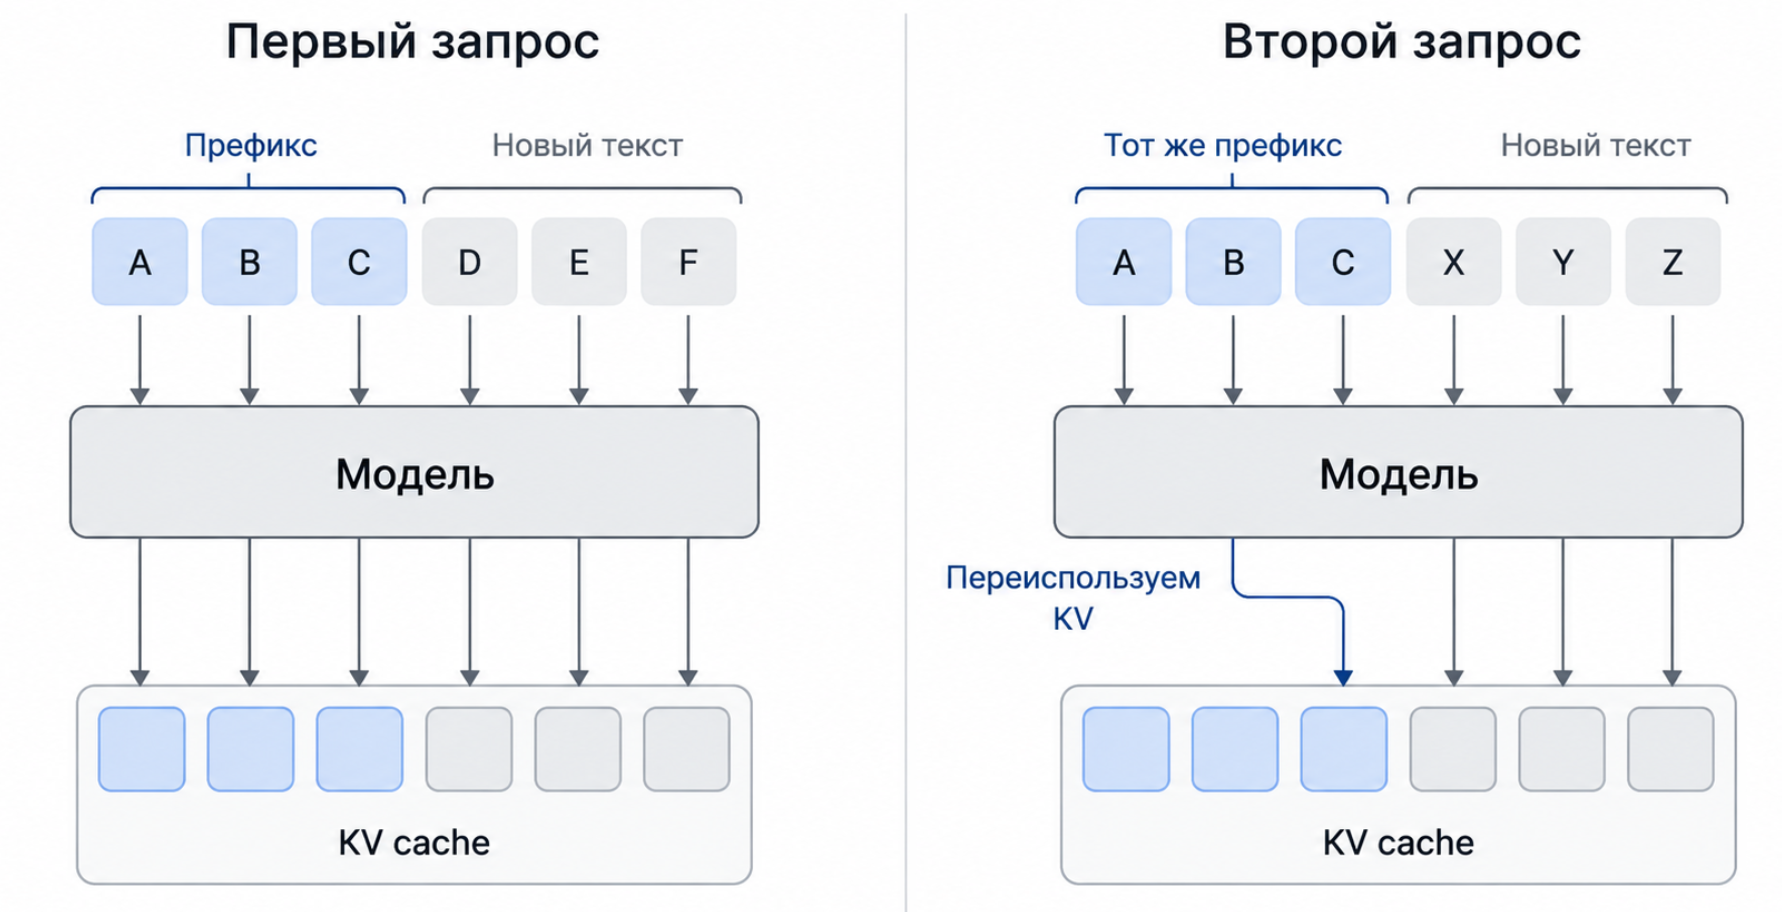

In [ ]:
common_context = "\n".join(
    f"Клиент {i}. Продажи за квартал {i * 1000} рублей. Статус активный."
    for i in range(1, 45)
)

common_context

In [ ]:
session_token = session_id_cvar.set(f"lesson-6-{uuid.uuid4()}")

try:
    cold = call_llm("Сколько записей клиентов приведено? Ответь числом.",
                    context=common_context)
    warm = call_llm("Какой статус указан у клиентов? Ответь кратко.",
                    context=common_context)
finally:
    session_id_cvar.reset(session_token)

display(pd.DataFrame([{
    "Запрос": label,
    "Кэшированные токены": call["cached_tokens"],
    "Оплачиваемые токены": call["paid_tokens"],
    "Стоимость, ₽": call["cost_rub"],
} for label, call in [("Первый", cold), ("Второй", warm)]]).round(5))

## Выбор более дешёвой модели

Не все узлы LLM-графа обязательно должны использовать одну и ту же модель. Например, генерацию содержательного ответа можно оставить сильной модели, а краткую оценку вариантов доверить более дешёвой. Такой подход может уменьшить стоимость при сохранении приемлемого качества, но его следует проверять на оценочной выборке.

Сначала выполним только **расчёт альтернативного сценария**, не отправляя новый запрос. Предположим, что последний узел Tree of Thoughts использует GigaChat 2 Lite и потребляет столько же токенов. В реальности число токенов, ответы и качество могут измениться.

In [ ]:
original_cost = sum(call["cost_rub"] for call in tree_run["calls"])
alternative_cost = sum(
    call["paid_tokens"] * PRICES[
        "GigaChat-2" if call["task"] == "select" else MAIN_MODEL
    ] / 1_000_000
    for call in tree_run["calls"]
)
print(f"Исходная стоимость графа {original_cost:.5f} ₽")
print(f"Оценка с более дешёвым узлом выбора {alternative_cost:.5f} ₽")
print(f"Предполагаемая экономия {original_cost - alternative_cost:.5f} ₽")

## Параллельные обращения к модели

Три генерации self-consistency независимы и могут выполняться одновременно. Это позволяет уменьшить время ожидания всего графа, хотя число обращений и оплачиваемых токенов само по себе не сокращается.

Для демонстрации используем `asyncio.to_thread`, который переносит блокирующий вызов SDK в отдельный поток. Такой приём позволяет показать параллельный запуск без изменения уже написанной функции `call_llm`. Здесь речь идёт о параллелизме клиентского кода, который следует отличать от отдельного асинхронного тарифного режима API.

In [ ]:
started = perf_counter()

parallel_calls = await asyncio.gather(*[
    asyncio.to_thread(call_llm, QUESTION, HISTORY, CRM_CONTEXT)
    for _ in range(3)
])
parallel_time = perf_counter() - started
sequential_time = sum(call["latency_s"] for call in consistency_run["calls"])

print(f"Последовательное выполнение {sequential_time:.2f} с")
print(f"Параллельное выполнение {parallel_time:.2f} с")
print(f"Стоимость параллельных вызовов {sum(c['cost_rub'] for c in parallel_calls):.5f} ₽")

## Контроль токенного бюджета и квот

Объём потребления обычно ограничивают на нескольких уровнях. Для отдельного выполнения можно задать максимальную стоимость или число токенов, а для всего приложения установить общий дневной либо месячный бюджет. Перед запросом такие ограничения проверяют по прогнозу, а после выполнения обновляют по фактическим данным.


In [ ]:
TOKEN_QUOTA = 20_000
COST_QUOTA = 15.0
RUN_TOKEN_LIMIT = 500

spent_tokens = int(monitor_df["paid_tokens"].sum())
spent_rub = float(monitor_df["cost_rub"].sum())


def quota_level(used, limit):
    share = used / limit
    if share >= 0.95:
        return "Критический порог"
    if share >= 0.80:
        return "Высокое потребление"
    if share >= 0.50:
        return "Половина бюджета"
    return "В пределах бюджета"


print(f"Токены {spent_tokens:,} из {TOKEN_QUOTA:,}", quota_level(spent_tokens, TOKEN_QUOTA))
print(f"Стоимость {spent_rub:.3f} из {COST_QUOTA:.2f} ₽", quota_level(spent_rub, COST_QUOTA))
exceeded = monitor_df.loc[monitor_df["paid_tokens"] > RUN_TOKEN_LIMIT, "trace_id"].tolist()
print("Превышен лимит отдельного запуска", exceeded if exceeded else "нет")

> **Вопрос**
>
> Какой из перечисленных приёмов сам по себе прежде всего уменьшает задержку независимых запросов, а не число оплачиваемых токенов?
>
> - **А.** Сокращение повторяющегося входного контекста за счёт кэширования.
> - **Б.** Параллельное выполнение нескольких независимых обращений к LLM.
> - **В.** Замена части вызовов более дешёвой генерационной моделью.
> - **Г.** Уменьшение максимального количества генерируемых токенов.

<details>
<summary>Ответ</summary>

**Правильный ответ Б.**

**А.** Кэширование способно уменьшить оплачиваемый объём входного контекста.

**Б.** Параллельность сокращает суммарное ожидание при независимых вызовах, но не уменьшает их токены автоматически.

**В.** Дешёвая модель снижает тариф на часть вызовов при сопоставимом потреблении.

**Г.** Ограничение длины генерации может сократить число выходных токенов и стоимость.

</details>

# Итоговый дашборд мониторинга

В завершение объединим результаты предыдущих разделов на одной панели. Она покажет общий расход токенов, стоимость, длительность выполнения, влияние повторных попыток и приближение к квотам.

В реальном сервисе аналогичные метрики обычно собираются непрерывно, а графики обновляются по мере появления новых трассировок. Для нашего примера достаточно одного статического представления, которое можно заново построить после выполнения остальных ячеек.

## Сводные показатели и стоимость успешного результата

При оценке эффективности важно учитывать не только стоимость вызовов, но и долю успешных выполнений. Рассчитаем средние расходы на один успешный результат. Поскольку при повторной генерации токены уже могли быть оплачены, такие расходы должны входить в числитель показателя.

В нашем сценарии ошибки искусственно моделируются внутри отдельных вызовов, а все показанные трассировки завершаются ответом. В реальном приложении необходимо дополнительно проверять правильность ответа, поскольку получение текста от модели ещё не гарантирует успешного решения задачи.

In [ ]:
successful = int(monitor_df["success"].sum())
cost_per_success = monitor_df["cost_rub"].sum() / successful if successful else float("nan")

print("Всего выполнений", len(monitor_df))
print("Успешных выполнений", successful)
print(f"Стоимость одного успешного выполнения {cost_per_success:.5f} ₽")

## Панель мониторинга

Для итоговой визуализации создадим четыре карточки ключевых показателей и несколько диаграмм. Здесь код намеренно немного объёмнее предыдущих примеров, поскольку эта ячейка служит иллюстрацией того, как знакомые метрики можно представить вместе.

In [ ]:
bg, panel, ink, muted, accent = "#282a2c", "#353739", "#f4f1eb", "#a9b0b1", "#f5bd9b"
fig = plt.figure(figsize=(14, 10), facecolor=bg)
grid = fig.add_gridspec(3, 4, height_ratios=[0.8, 1.9, 1.6], hspace=0.65, wspace=0.24)

cards = [
    ("ТРАССИРОВОК", str(len(monitor_df))),
    ("ОПЛАЧЕННЫХ ТОКЕНОВ", f"{spent_tokens:,}"),
    ("ОБЩАЯ СТОИМОСТЬ", f"{spent_rub:.3f} ₽"),
    ("ЗАДЕРЖКА P95", f"{monitor_df['latency_s'].quantile(.95):.2f} с"),
]
for column, (label, value) in enumerate(cards):
    ax = fig.add_subplot(grid[0, column])
    ax.set_facecolor(panel)
    ax.text(0.06, 0.72, label, color=muted, fontsize=10, transform=ax.transAxes)
    ax.text(0.06, 0.25, value, color=ink, fontsize=23, weight="bold", transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

def dark_axis(ax, title):
    ax.set_facecolor(panel)
    ax.set_title(title, color=ink, fontsize=12, loc="left", pad=15)
    ax.tick_params(colors=muted, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.grid(axis="y", color=muted, alpha=0.15)
    ax.set_axisbelow(True)

ax = fig.add_subplot(grid[1, :2])
dark_axis(ax, "Стоимость полных выполнений")
ax.bar(monitor_df["trace_id"], monitor_df["cost_rub"], color=accent)
ax.set_xlabel("Номер трассировки", color=muted)
ax.set_ylabel("Рубли", color=muted)

ax = fig.add_subplot(grid[1, 2:])
dark_axis(ax, "Задержка и 95-й перцентиль")
ax.plot(monitor_df["trace_id"], monitor_df["latency_s"], color=accent, marker="o", lw=1.8)
ax.axhline(monitor_df["latency_s"].quantile(.95), color=muted, linestyle="--", label="p95")
ax.legend(frameon=False, labelcolor=ink)
ax.set_xlabel("Номер трассировки", color=muted)
ax.set_ylabel("Секунды", color=muted)

ax = fig.add_subplot(grid[2, :2])
dark_axis(ax, "Оплаченные токены по типам")
ax.bar(monitor_df["trace_id"], monitor_df["input_tokens"], color=muted, label="Вход")
ax.bar(monitor_df["trace_id"], monitor_df["output_tokens"],
       bottom=monitor_df["input_tokens"], color=accent, label="Генерация")
ax.legend(frameon=False, labelcolor=ink, ncol=2)
ax.set_xlabel("Номер трассировки", color=muted)

ax = fig.add_subplot(grid[2, 2:])
dark_axis(ax, "Квота токенов")
quota_share = min(spent_tokens / TOKEN_QUOTA, 1)
ax.barh([0], [1], color="#55595c", height=0.34)
ax.barh([0], [quota_share], color=accent, height=0.34)
ax.text(0.02, 0.70, f"{spent_tokens:,} / {TOKEN_QUOTA:,} токенов", color=ink,
        fontsize=13, transform=ax.transAxes)
ax.text(0.02, 0.17, f"Средняя стоимость успешного результата  {cost_per_success:.4f} ₽",
        color=muted, fontsize=10, transform=ax.transAxes)
ax.text(0.02, 0.05, f"Повторных попыток  {int(monitor_df['retries'].sum())}",
        color=muted, fontsize=10, transform=ax.transAxes)
ax.set_xlim(0, 1)
ax.set_ylim(-0.8, 0.8)
ax.set_xticks([])
ax.set_yticks([])

fig.suptitle("Мониторинг стоимости LLM (для self-consistency)", color=ink, fontsize=19,
             weight="bold", x=0.08, y=0.99, ha="left")
plt.show()

В полученной панели метрики имеют разное назначение. Общая стоимость показывает сумму расходов на наблюдаемом периоде, перцентили позволяют обнаруживать медленные выполнения, а показатели квот предупреждают о приближении к заранее установленным ограничениям. Стоимость успешного результата дополняет эти измерения и позволяет связывать расход ресурсов с практической пользой приложения.

# Заключение

Таким образом, на данном занятии мы научились рассчитывать стоимость обращений к LLM на основе фактического потребления токенов и определять вклад различных компонентов запроса. Мы сравнили стоимость базовой генерации, self-consistency и Tree of Thoughts, после чего рассмотрели оценку токенного бюджета на выборке пользовательских задач. Далее мы познакомились с трассировкой выполнения, мониторингом задержек и стоимости, повторными попытками вызовов и перцентилями распределения метрик. Кроме того, мы разобрали кэширование контекста, использование более дешёвых моделей, параллельное выполнение независимых запросов и контроль квот, а в завершение объединили изученные показатели в простую панель мониторинга LLM-приложения.